# Lab session 2: Clustering with Python

In this session, we will explore the unsupervised learning task of clustering. The first part of this exercise will let you play around standard clustering methods on different data example. In the following part, we explore *good practices* for clustering data. The last section consists of an open-ended real-world application. 

In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import tqdm 
import pandas as pd

from course_checks import grader

# Part 1. Clustering

## Exercise 1. Spectral Clustering from scratch
The goal is to implement Spectral Clustering as described in Luxburg's tutorial: https://people.csail.mit.edu/dsontag/courses/ml14/notes/Luxburg07_tutorial_spectral_clustering.pdf. We will start with implementing different part of the algorithm and work towards the standard object-oriented language used in `sklearn`. 


### Question 1. Similarity graph
Implement a function that constructs the similarity graph $S \in \mathbb{R}^{N \times N}$ for a given set of points $x_1, \cdots, x_n$ based on the three criteria:
1) $\epsilon$-neighborhood graph: $S_{i,j} = 1$ if $||x_i - x_j||_2 \leq \epsilon$, $S_{i,j} = 0$ otherwise.
2) $k$-nearest neighbor graph: $S_{i,j} = 1$ if $i$ is among the $k$ nearest neighbors of $j$. $S_{i,j} = 0$ otherwise.
3) fully connected graph with weighted distance: $S_{i,j} = \exp(-||x_i-x_j||^2/(2\sigma^2))$

The suggested roadmap is to break it down into 3 standalone functions that will be called by `compute_similarity`.

**Check convention:** Exclude self-edges in all graphs. In kNN, count the `k` nearest *other* observations. The stated directed convention is `S[i, j] = 1` when `i` is a neighbor of `j`. Before spectral clustering, symmetrize kNN adjacency (for example, `W = np.maximum(S, S.T)`) so the Laplacian is symmetric.


In [2]:
from scipy.spatial.distance import pdist, squareform

def epsilon_neighbor(X, eps=1.0):
    # TODO: Compute the quantity for epsilon neighborhood graph
    raise NotImplementedError("Complete epsilon_neighbor")

In [ ]:
# If X shape is (n, p)
# X[:, None, :] shape is (n, 1, p)
# X[None, :, :] shape is (1, n, p)
diff = X[:, None, :] - X[None, :, :]  # Shape: (n, n, p)
# Square the differences, sum along the coordinate axis, and take the square root
pairwise_distances = np.sqrt(np.sum(diff**2, axis=-1)) # equivalent to squareform(pdist(D**2, 'euclidean')) or squareform(pdist(D, 'sqeuclidean'))

In [2]:
from sklearn.neighbors import NearestNeighbors
help(NearestNeighbors)

Help on class NearestNeighbors in module sklearn.neighbors._unsupervised:

class NearestNeighbors(sklearn.neighbors._base.KNeighborsMixin, sklearn.neighbors._base.RadiusNeighborsMixin, sklearn.neighbors._base.NeighborsBase)
 |  NearestNeighbors(*, n_neighbors=5, radius=1.0, algorithm='auto', leaf_size=30, metric='minkowski', p=2, metric_params=None, n_jobs=None)
 |  
 |  Unsupervised learner for implementing neighbor searches.
 |  
 |  Read more in the :ref:`User Guide <unsupervised_neighbors>`.
 |  
 |  .. versionadded:: 0.9
 |  
 |  Parameters
 |  ----------
 |  n_neighbors : int, default=5
 |      Number of neighbors to use by default for :meth:`kneighbors` queries.
 |  
 |  radius : float, default=1.0
 |      Range of parameter space to use by default for :meth:`radius_neighbors`
 |      queries.
 |  
 |  algorithm : {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'
 |      Algorithm used to compute the nearest neighbors:
 |  
 |      - 'ball_tree' will use :class:`BallTree

In [ ]:
from sklearn.neighbors import NearestNeighbors
def k_nearest_neighbor(X, n_neighbors=5, symmetrize=False):
    N = X.shape[0]
    S = np.zeros((N, N))
    nn = NearestNeighbors(n_neighbors=n_neighbors+1, metric='euclidean').fit(X)
    D = nn.kneighbors_graph(X).toarray()
    np.fill_diagonal(D, 0)
    if symmetrize:
        return np.maximum(D, D.T)
    return D

In [3]:
def k_nearest_neighbor(X, n_neighbors=5):
    # TODO: Compute the quantity for k nearest neighbor graph
    raise NotImplementedError("Complete k_nearest_neighbor")

In [4]:
def gaussian_kernel_neighbor(X, sigma=1):
    # TODO: Compute the quantity for the fully connected graph with gaussian kernel weights
    raise NotImplementedError("Complete gaussian_kernel_neighbor")

In [5]:
def compute_similarity(X, graph='epsilon', n_neighbors=5, eps=1.0, sigma=1):
    # TODO: Fill in the function that returns the correct similarity graph
    raise NotImplementedError("Complete compute_similarity")

In [4]:
# Verify your solutions here: 
grader.check("epsilon_neighbor", epsilon_neighbor)
grader.check("k_nearest_neighbor", k_nearest_neighbor)
grader.check("gaussian_kernel_neighbor", gaussian_kernel_neighbor)
grader.check("compute_similarity", compute_similarity)


NameError: name 'epsilon_neighbor' is not defined

### Question 2. Graph Laplacian

Spectral Clustering requires to compute the graph Laplacian. The paper linked earlier details different strategies. We will focus on the *unnormalized graph Laplacian* defined as $L = D-W$ where $D$ is the degree matrix, and $W$ is the weighted adjacency matrix. In practice, $W$ is a transformation of $S$ that enforces stronger local connectedness. For a simplified version, we will take $W := S$. Then the degree matrix $D$ is defined as the diagonal matrix such that $D_{i,i}=\sum_j W_{i,j}$. 


In [7]:
def graph_laplacian(S):
    # TODO: Compute L = D - S
    raise NotImplementedError("Complete graph_laplacian")


In [ ]:
def graph_laplacian(S):
    n = S.shape[0]
    D = np.zeros((n,n))
    for i in range(n):
        D[i, i] = np.sum(S[i,:])
    return D - S

In [8]:
# Verify your solutions here: 
grader.check("graph_laplacian", graph_laplacian)

AssertionError: Lab 2, Ex1 Q2: unnormalized Laplacian, case 1: raised NotImplementedError: Complete graph_laplacian

### Question 3. Eigenvectors 

Now that you have the graph Laplacian $L$, write a function that returns the $k$ first eigenvectors of $L$. 

In [9]:
from scipy.linalg import eigh 
def get_eigenvectors(L, k=5):
    # TODO: Compute U = [u_1, ..., u_k] with L u_i = a_i * u_i with a_1 =< a_2 ... =< a_n
    raise NotImplementedError("Complete get_eigenvectors")

In [5]:
from scipy.linalg import eigh
help(eigh)

Help on function eigh in module scipy.linalg._decomp:

eigh(a, b=None, *, lower=True, eigvals_only=False, overwrite_a=False, overwrite_b=False, type=1, check_finite=True, subset_by_index=None, subset_by_value=None, driver=None)
    Solve a standard or generalized eigenvalue problem for a complex
    Hermitian or real symmetric matrix.
    
    Find eigenvalues array ``w`` and optionally eigenvectors array ``v`` of
    array ``a``, where ``b`` is positive definite such that for every
    eigenvalue λ (i-th entry of w) and its eigenvector ``vi`` (i-th column of
    ``v``) satisfies::
    
                      a @ vi = λ * b @ vi
        vi.conj().T @ a @ vi = λ
        vi.conj().T @ b @ vi = 1
    
    In the standard problem, ``b`` is assumed to be the identity matrix.
    
    The documentation is written assuming array arguments are of specified
    "core" shapes. However, array argument(s) of this function may have additional
    "batch" dimensions prepended to the core shape. In th

In [10]:
grader.check("get_eigenvectors", get_eigenvectors)


AssertionError: Lab 2, Ex1 Q3: smallest eigenvectors, case 1: raised NotImplementedError: Complete get_eigenvectors

In [11]:
# Verify your solutions here: 
grader.check("get_eigenvectors", get_eigenvectors)

AssertionError: Lab 2, Ex1 Q3: smallest eigenvectors, case 1: raised NotImplementedError: Complete get_eigenvectors

### Question 4. Spectral Clustering

We are about to wrap up writing the Spectral Clustering algorithm. Now it remains to cluster using KMeans clustering on the rows of $U \in \mathbb{R}^{N \times k}$ into clusters $C_1, \cdots, C_k$. *Note that this version requires that your nearest neighbor algorithm uses the symmetrized similarity before computing the Graph Laplacian.*

In [12]:
# For reproducible comparisons, use KMeans(n_clusters=n_clusters, random_state=123, n_init=10)
from sklearn.cluster import KMeans
def spectral_clustering(X, n_clusters=3, graph = 'gaussian', eps=1.0, sigma=1.0, n_neighbors=5):
    S = compute_similarity(X, graph=graph, n_neighbors=n_neighbors, eps=eps, sigma=sigma)
    L = graph_laplacian(S)
    U = get_eigenvectors(L, k=n_clusters)
    # TODO: Fill in this section to complete spectral clustering
    raise NotImplementedError("Complete spectral_clustering") 

In [13]:
grader.check("spectral_clustering", spectral_clustering)


AssertionError: Lab 2, Ex1 Q4: spectral clustering, case 1: raised NotImplementedError: Complete compute_similarity

### Question 5. Toy dataset
Let's apply our version vs the typical `sklearn` implementation on a toy dataset. Compare the clustering assignments obtained with `KMeans`, `SpectralClustering` and your version.

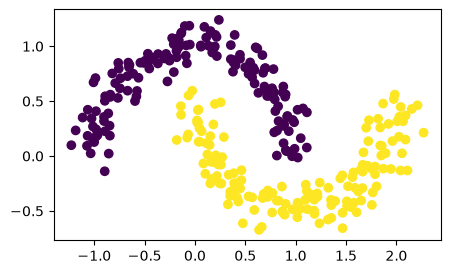

In [14]:
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=300, noise=0.1, random_state=42)
plt.figure(figsize=(5,3))
plt.scatter(X[:,0], X[:,1], c=y)

In [15]:
from sklearn.cluster import KMeans, SpectralClustering
# TODO: Compare your implementation with Spectral Clustering from sklearn, and compare with KMeans. 


In [16]:
# TODO: plot the data colored by clustering solutions

# Part 2. Model selection for clustering

## Exercise 2. Standard clustering algorithms

In this short exercise, you will be applying standard clustering algorithms from the `scikit-learn` package on toy datasets. 

### Question 1. Simulating data
Let $\pi = [0.2, 0.5, 0.3]$. Set $N=1000$ across all 3 datasets.
* Simulate a gaussian mixture with 3 components and two features as follows: 
    - $y \sim \text{Mult}(\pi, 1)$ and $X \ |\ y=k \sim N(\mu_k, \sigma_k^2 I_2)$ for $k \in \{1, 2, 3\}$ 
    - with $\mu_1 = [-3, 3], \ \mu_2 = [3, -3]$ and $\mu_3 = [3, 0.5]$, $\sigma_1 = 1.5, \sigma_2 = 1.0, \sigma_3=0.5$. 
* Use `sklearn.datasets.make_moons` to generate the interlaced moon dataset. 
* Sample from three uniform distributions: $X\ | \ y=k \sim \text{Unif}(r_k)$ with $r_1 = [[-1, -0.5],[-0.5, 1]]$, $r_2 = [[-0.1, 0.2],[0.8, 1]]$ and $r_3 = [[0.3, -1], [0.7,-0.2]]$.

In [17]:
from sklearn.datasets import make_moons
# TODO:... 
dataset_dict = {}
# TODO: ...
dataset_dict['GMM'] = {'data': X, 'label': y}
dataset_dict['moons'] = {'data':X, 'label': y}
dataset_dict['uniform'] = {'data': X, 'label': y}

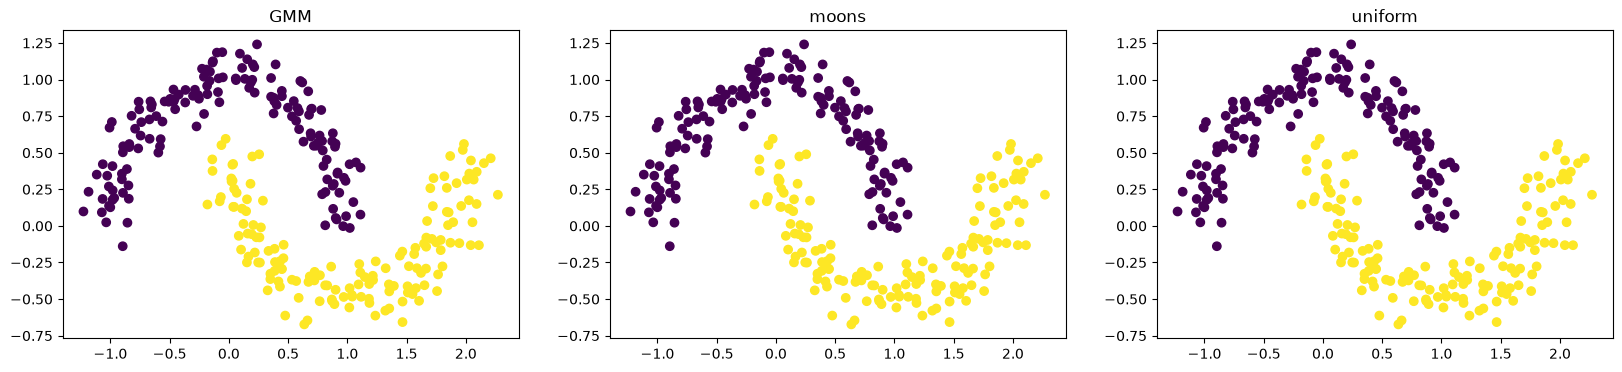

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
for i, data in enumerate(dataset_dict):
    ax[i].scatter(dataset_dict[data]['data'][:, 0],dataset_dict[data]['data'][:, 1], c=dataset_dict[data]['label'])
    ax[i].set_title(data)

### Question 2. Applying clustering algorithms

Read this page: https://scikit-learn.org/stable/modules/clustering.html. Apply 4 of the standard clustering algorithms to the 3 datasets. Carefully check the hyperparameters of your chosen methods. In a 3 by 5 plot, show the data colored by the predicted labels for each dataset and each clustering method. The first column should contain the data colored with its original labels. 

In [19]:
from sklearn.cluster import SpectralClustering, KMeans, AgglomerativeClustering, DBSCAN 
# TODO: ...

### Question 3. Hierarchical Clustering
In a previous lab, you have used hierarchical clustering with the `scipy` package via `scipy.cluster.hierarchy`'s function. The goal of this question is to compare using `sklearn`'s Agglomerative Clustering with `n_clusters=None` and `scipy`'s `linkage` on the half-moon dataset.


1) Choose to apply `scipy`'s `linkage` function on the half-moon dataset. Plot out the dendrogram associated with the hierarchical clustering. 

In [20]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
X, y = dataset_dict['moons']['data'], dataset_dict['moons']['label']
# TODO: ...


2) Apply `scipy.cluster.hierarchy`'s `fcluster` function to obtain the flat clusters' associated with hierarchical clustering with your linkage matrix - use `distance` as criterion to apply for forming clusters. Choose  3 values for distance threshold based on your plotted dendrogram from the previous question. Plot the data colored by the learnt cluster labels.

In [21]:
from scipy.cluster.hierarchy import fcluster
# TODO: ...

3. Apply `sklearn`'s `AgglomerativeClustering` with `distance_threshold` and set `n_clusters=None`. Make sure you use comparable methods across both `sklearn` and `scipy` algorithms, ie using `ward` for Ward's variance minimization algorithm for both, `single` for single linkage (ie nearest point algorithm), etc. Plot the dendrogram and the data colored by the cluster labels for the same 3 distance threshold values. Comment on the result.

*Hint: there isn't a dendrogram built-in plotting function in the `sklearn` object, instead reconstruct the linkage matrix and use `scipy.cluster.hierarchy`'s `dendrogram`. Recall that a linkage matrix is defined by a 
 $(n-1)$ by 4 matrix $Z$ where at $i$-th iteration, clusters with indices $Z[i, 0]$ and $Z[i, 1]$ are combined to form cluster $n+i$. A cluster with an index less than $n$ corresponds to one of the 
 original observations. The distance between clusters $Z[i, 0]$ and $Z[i, 1]$ is given by $Z[i, 2]$. The fourth value $Z[i, 3]$ represents the number of original observations in the newly formed cluster.*

In [22]:
from sklearn.cluster import AgglomerativeClustering
# TODO: ...

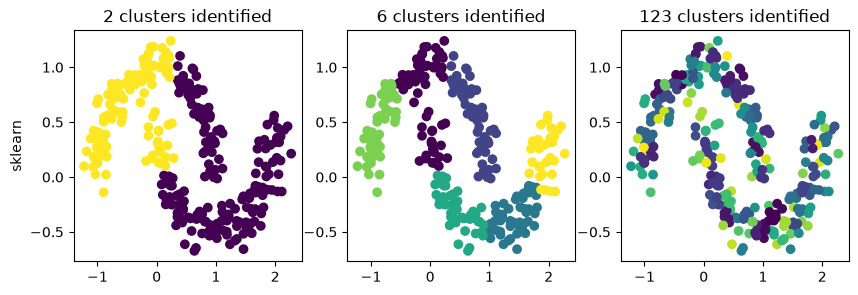

In [23]:
from sklearn.cluster import AgglomerativeClustering

dist_thresh = [1.4, 0.8, 0.1]
fig, ax = plt.subplots(1, 3, figsize=(10,3))
for i, t in enumerate(dist_thresh):
    AC = AgglomerativeClustering(n_clusters=None, distance_threshold=t, metric='euclidean', linkage='average')
    y_sk_hc = AC.fit_predict(X)
    ax[i].scatter(X[:, 0], X[:, 1], c=y_sk_hc)
    ax[i].set_title(f"{len(np.unique(y_sk_hc))} clusters identified")
    ax[0].set_ylabel('sklearn')

## Exercise 3. Choosing $K$, model selection and validation

[See this Stack Exchange discussion on clustering validation](https://stats.stackexchange.com/questions/195456/how-to-select-a-clustering-method-how-to-validate-a-cluster-solution-to-warran)


### Introduction.
How does one decide which method to choose and what hyperparameters? We are going to explore some commonly applied metrics to evaluate cluster quality and choosing the number of clusters. Two big families of validation metrics can be found in the literature around clustering: *external* validation indices and *internal* validation indices. 

#### External validation indices 

The following metrics are defined to compare two cluster solutions/partitions. Let $X = \{X_1, \ldots, X_r\}$ and $Y = \{Y_1, \ldots, Y_s\}$ where $X_1$ contains observations belonging to cluster 1 in partition $X$, $Y_1$ observations belonging to cluster 1 in partition $Y$. We introduce **RI**, **ARI** two agreement similarity measures, **NMI** and **AMI** two information similarity measures. These are external validation indices as they compare two groupings' similarity and can be used when one of the grouping is a reference ground truth. We will see how they can be used to validate in the absence of ground truth for clustering.

* **Rand Index**. Similarity metrics that reflects the similarities between two cluster groupings/partitions considering all pairs of samples and counting pairs assigned in the same or different clusters for the two groupings being compared. $$R = \frac{\#\{\text{ Agreements in } X \text{ and }Y \}}{\binom{n}{2}}$$


* **ARI: adjusted rand-index**. Adjusted rand-index is a similarity index between two partitions. It can be defined via the Rand index "corrected for chance", or via a contingency table summarizing the common objects between the two partitions. Define $n_{ij} = |X_i \cap Y_j|$ the overlap between cluster $i$ in the cluster partition $X$  and cluster $j$ in the cluster partition $Y$.  Then the contingency table for $X$ and $Y$ is given as below

<center>

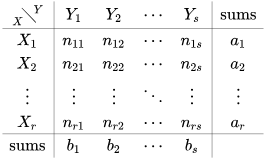

with the ARI essentially comparing how often two clusterings agree, with agreement not due to random chance. 
</center>

$$ARI =  \frac{\sum_{ij} \binom{n_{ij}}{2} - \bigg[\sum_i \binom{a_{ij}}{2} \sum_j \binom{b_{ij}}{2}\bigg] / \binom{n}{2}}{\frac{1}{2} \bigg[\sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2} \bigg] - \bigg[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\bigg] / \binom{n}{2}}$$
An $ARI = 0$ corresponds to random labelling (essentially $X \perp Y$), and $ARI=1$ matched partitions. 

* **NMI: normalized mutual information**. Normalized mutual information between two clustering, based on the mutual information between two groupings/partitions where 
$$MI(X, Y) = \sum_{i=1}^{r}\sum_{j=1}^{s} \frac{n_{ij}}{n} \log\big(\frac{n \times n_{ij}}{a_{i} b_{j}} \big)$$

and normalized so that $NMI = 0$ means no mutual information ie clusterings that are produced by two independent distributions for $X$ and $Y$, and $NMI=1$ is a perfect correlation. 

* **AMI: adjusted mutual information**. Adjusted-MI adjust for chance, the MI is higher for two clusterings with a larger number of clusters regardless of information shared, so we adjust using 
$$AMI(X, Y) = \frac{MI(X, Y)- \mathbb{E}(MI(X, Y))}{1/2 \bar{H}(X) \bar{H}(Y) - \mathbb{E}(MI(X, Y))}$$
where $\bar{H}(X) = - \frac{1}{s} \sum_{i=1}^s \frac{a_i}{n} \log \frac{a_i}{n}$ the Shannon entropy associated with partition $X$. 
An $AMI = 0$ is obtained for independent $X$, $Y$ while $AMI=1$ is perfectly matched partition. Similar to the ARI, there can be a negative value for non random, non matched partitions. 

#### Internal validation indices

Internal validation indices typically rely on some assumption on the data: compute some statistics/metric of geometrical properties of the data clustering that would correspond to the practitionner definition of a "good" clustering. These indices typically involve balancing notions of *cohesion* for each cluster and *separation* across different clusters. We will only see the silhouette scores, but multiple indices exist including the Davies-Bouldin index, Calinski-Harabasz index etc.

* **Silhouette score**: Silhouette Coefficient is calculated based on the mean intra-cluster distance $\alpha$ and mean nearest-cluster distance $\beta$ for each sample. Essentially, it measures a score that reflects cohesion within each clusters and separation across different clusters. For each sample $i$ in a cluster $C_{i}$, 
$$\alpha(i) = \frac{1}{|C_{i}|-1} \sum_{j \in C_i, i\neq j} d(i,j), \qquad \beta(i) = \min_{j\neq i} \sum_{l \in C_j} d(i, l)$$
Then the per-sample silhouette score is defined as 
$$S(i) = \begin{cases} \frac{\beta(i)-\alpha(i)}{\max \{\alpha(i), \beta(i)\}} & \ |C_i| > 1 \\ 
         0 & \text{ if } |C_i| = 1\end{cases} $$




### Question 1. Internal validation of clustering
Use one of the datasets of **Exercise 2, Q1** and a clustering algorithm among the ones you have seen so far. Calculate the average silhouette score of the clustering for that algorithm for a range of $K$ (or equivalent hyperparameter) and plot the average silhouette score against the values of $K$. What choices did you make? Comment on your results.

In [24]:
from sklearn.metrics import silhouette_score
# TODO: ...

### Question 2. External validation metrics

1) As before, choose a different dataset from our simulated examples in **Exercise 2, Q1** and a clustering algorithm that we have seen, compute the external validation metrics against the true generated labels. Plot out the results of each metric against $K$ (or the hyperparameter with corresponding $K$).


In [25]:
from sklearn.metrics import rand_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score
# TODO: ... 

2. Now consider the case where you do not have access the ground truth labels. Propose a way to validate your clustering based on external indices.

<details>
  <summary><b>Click to reveal the spoiler for this question</b></summary>
  
  * Use stability as a measure of validation: choose $K$ that stabilizes the external validation metric. 
  * Use generalizability as a measure of validation: choose $K$ that generalizes the best on unseen data.
  
</details>

3. Implement your approach to validate clustering based on external indices. Apply it on the same data as before. Load the `literary_styles.csv` data and apply the same validation approach to this data and a choosen clustering algorithm.

In [26]:
import pandas as pd
data = pd.read_csv("../data/literary_styles_dataset.csv")
data.head() 
literary_data, metadata = data.iloc[:, 6:], data.iloc[:, :6]
metadata.head()


,Author,BookID,Title,GutenbergID,BlockID,BlockWords
0,Austen,1,Sense and Sensibility,161,1,1700
1,Austen,1,Sense and Sensibility,161,2,1700
2,Austen,1,Sense and Sensibility,161,3,1700
3,Austen,1,Sense and Sensibility,161,4,1700
4,Austen,1,Sense and Sensibility,161,5,1700


In [27]:
def my_approach(X, labels):
    # TODO: ...
    return


<details>
  <summary> 4. Click for next question. </summary>

 Stability for clustering validation:
 * For $k=2, \cdots, K_{max}$, 
    * for $i=1, \cdots, M$,
      * subsample fraction of the data  $X_{S_1^{(m)}}$, and get cluster labels $L_1^{(m,k)}$
      * subsample another fraction of the data  $X_{S_2^{(m)}}$, and get cluster labels $L_2^{(m,k)}$
      * Compute external validity index on the intersection of the labels 
      $$v_m = \operatorname{validity}(\{L_{1, i}^{(m,k)}, i \in S_1^{(m,k)}\cap S_2^{(m,k)} \},\{   L_{2,i}^{(m,k)}, i \in S_1^{(m)}\cap S_2^{(m,k)} \})$$
    * Return $\bar v_k = \frac{1}{M} \sum_{m} v_m$, $\hat{se}(v)_k$
  * Choose $K^*$ that yields highest $\bar v_k$


  Reference: https://psb.stanford.edu/psb-online/proceedings/psb02/benhur.pdf 

  </details>

In [28]:
def stability(X, model, M, subsample_ratio, **kwargs):
    # TODO: ...
    return 

In [29]:
grader.check_stability(stability)


TypeError: stability() got multiple values for argument 'M'

5. Conclude and choose the clustering solution for the data example. What are the clusters? What about changing algorithm method? 


...

# Bonus: 
Explore `carve-validate` a Clustering validation package: https://github.com/DataSlingers/CARVE. 
Install using `pip install carve-validate`. You will need to upgrade to Python 3.13, create a new environment (recommended) for this. Read through the documentation and play around with the validation toolkit made available. 

In [ ]:
from carve import CARVE
# TODO:...